# Universidad Autonoma de Aguascalientes
# Departamento: Ciencias de la Computacion
# Carrera: Ingenieria en Computacion Inteligente
## Curso: Lenguajes Inteligentes
## Maestro: Dr.Francisco Javier Lunas Rosas
## Alumno: Luis Fernando Silva Briones
## Semestre: Agosto_Diciembre del 2026

### 1. ¿Qué puedes hacer con NLTK?

### Estas son algunas de sus principales aplicaciones:

### Tokenización. Separar un texto en palabras o frases.

### Eliminación de Stopwords. Eliminar palabras poco importantes como el, la, de, y.

### Frecuencia de palabras. Contar cuántas veces aparece cada palabra.

## Practica #4. WordCloud (Quijote).

## El WordCloud (nube de palabras) sirve para visualizar de forma gráfica las palabras más frecuentes en un texto.

### El WordCloud toma un texto, cuenta cuántas veces aparece cada palabra, y luego muestra esas palabras en una imagen donde:

### Las palabras más grandes son las que más se repiten.

### Las palabras pequeñas son las menos frecuentes.

## En esta practica implementaremos un ejemplo de procesamiento de Lenguaje Natural utilizando la libreria NLTK para contar cuántas veces aparece cada palabra y la graficaremos utilizando la libreria WordCloud.

## Paso 1: Importamos librerias necesarias

In [1]:
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from wordcloud import WordCloud
from collections import Counter

## Paso 2. Leer el texto de El Quijote desde el archivo txt.

In [3]:
ruta = r"C:\Users\silva\Desktop\ICI\ICI quinto semestre\LENGUAJES INTELIGENTES\quijote.txt"

with open(ruta, 'r', encoding='latin-1') as archivo:
    texto = archivo.read()

print("Texto cargado exitosamente. Longitud:", len(texto), "caracteres.")

Texto cargado exitosamente. Longitud: 1018278 caracteres.


## Paso 3. Dividir el texto en palabras (tokens).

In [4]:
# Convertir el texto a minúsculas
texto = texto.lower()

# Separar el texto en palabras utilizando NLTK
palabras = word_tokenize(texto, language='spanish')

# Solo imprimimos las primeras 50 palabras para no saturar la salida
print("\nPalabras originales (primeras 50):")
print(palabras[:50])


Palabras originales (primeras 50):
['primera', 'parte', 'capítulo', '1', ':', 'que', 'trata', 'de', 'la', 'condición', 'y', 'ejercicio', 'del', 'famoso', 'hidalgo', 'd.', 'quijote', 'de', 'la', 'mancha', 'en', 'un', 'lugar', 'de', 'la', 'mancha', ',', 'de', 'cuyo', 'nombre', 'no', 'quiero', 'acordarme', ',', 'no', 'ha', 'mucho', 'tiempo', 'que', 'vivía', 'un', 'hidalgo', 'de', 'los', 'de', 'lanza', 'en', 'astillero', ',', 'adarga']


## Paso 4. Eliminar las stopwords (palabras vacias como: 'el','de','que',...)

In [5]:
# Obtener las palabras que no aportan informacion
stop_words = set(stopwords.words('spanish'))

# Eliminar signos de puntuacion y stopwords
palabras_limpias = [
    palabra for palabra in palabras
    if palabra.isalpha() and palabra not in stop_words
]

print("\nPalabras despues de la limpieza (primeras 50):")
print(palabras_limpias[:50])


Palabras despues de la limpieza (primeras 50):
['primera', 'parte', 'capítulo', 'trata', 'condición', 'ejercicio', 'famoso', 'hidalgo', 'quijote', 'mancha', 'lugar', 'mancha', 'cuyo', 'nombre', 'quiero', 'acordarme', 'tiempo', 'vivía', 'hidalgo', 'lanza', 'astillero', 'adarga', 'antigua', 'rocín', 'flaco', 'galgo', 'corredor', 'olla', 'vaca', 'carnero', 'salpicón', 'noches', 'duelos', 'quebrantos', 'sábados', 'lentejas', 'viernes', 'algún', 'palomino', 'añadidura', 'domingos', 'consumían', 'tres', 'partes', 'hacienda', 'resto', 'della', 'concluían', 'sayo', 'velarte']


## Paso 5. Contar la frecuencia de las palabras.

In [6]:
frecuencias = Counter(palabras_limpias)

print("\nFrecuencias de palabras (Top 20):")
print(frecuencias.most_common(20))


Frecuencias de palabras (Top 20):
[('don', 1070), ('si', 971), ('tan', 753), ('quijote', 706), ('dijo', 593), ('sancho', 582), ('así', 534), ('bien', 533), ('ser', 506), ('pues', 407), ('señor', 402), ('merced', 400), ('caballero', 347), ('sino', 318), ('hacer', 318), ('dos', 301), ('aquel', 297), ('cosa', 281), ('aunque', 268), ('decir', 266)]


## Paso 6. Generar la nube de palabras.

In [9]:
nube = WordCloud(
    width=2400,              # Imagen más grande para que quepan más palabras
    height=1200,
    background_color='white',
    colormap='viridis',
    max_words=1000,           # Antes 150: ahora se muestran hasta 1000 palabras
    max_font_size=260,       # Limita el tamaño de las palabras más grandes ('don', 'quijote'...)
    min_font_size=10,        # Evita palabras demasiado pequeñas e ilegibles
    relative_scaling=0.25,   # Reduce la diferencia de tamaño entre palabras frecuentes y poco frecuentes
    prefer_horizontal=0.85,  # Permite algunas palabras verticales para aprovechar el espacio
    margin=2,
    random_state=42          # Misma distribución cada vez que se ejecuta
).generate_from_frequencies(frecuencias)

print("Palabras distintas en el texto:", len(frecuencias))
print("Palabras dibujadas en la nube:", len(nube.layout_))

Palabras distintas en el texto: 14163
Palabras dibujadas en la nube: 1000


## Paso 7. Mostrar la nube de palabras.

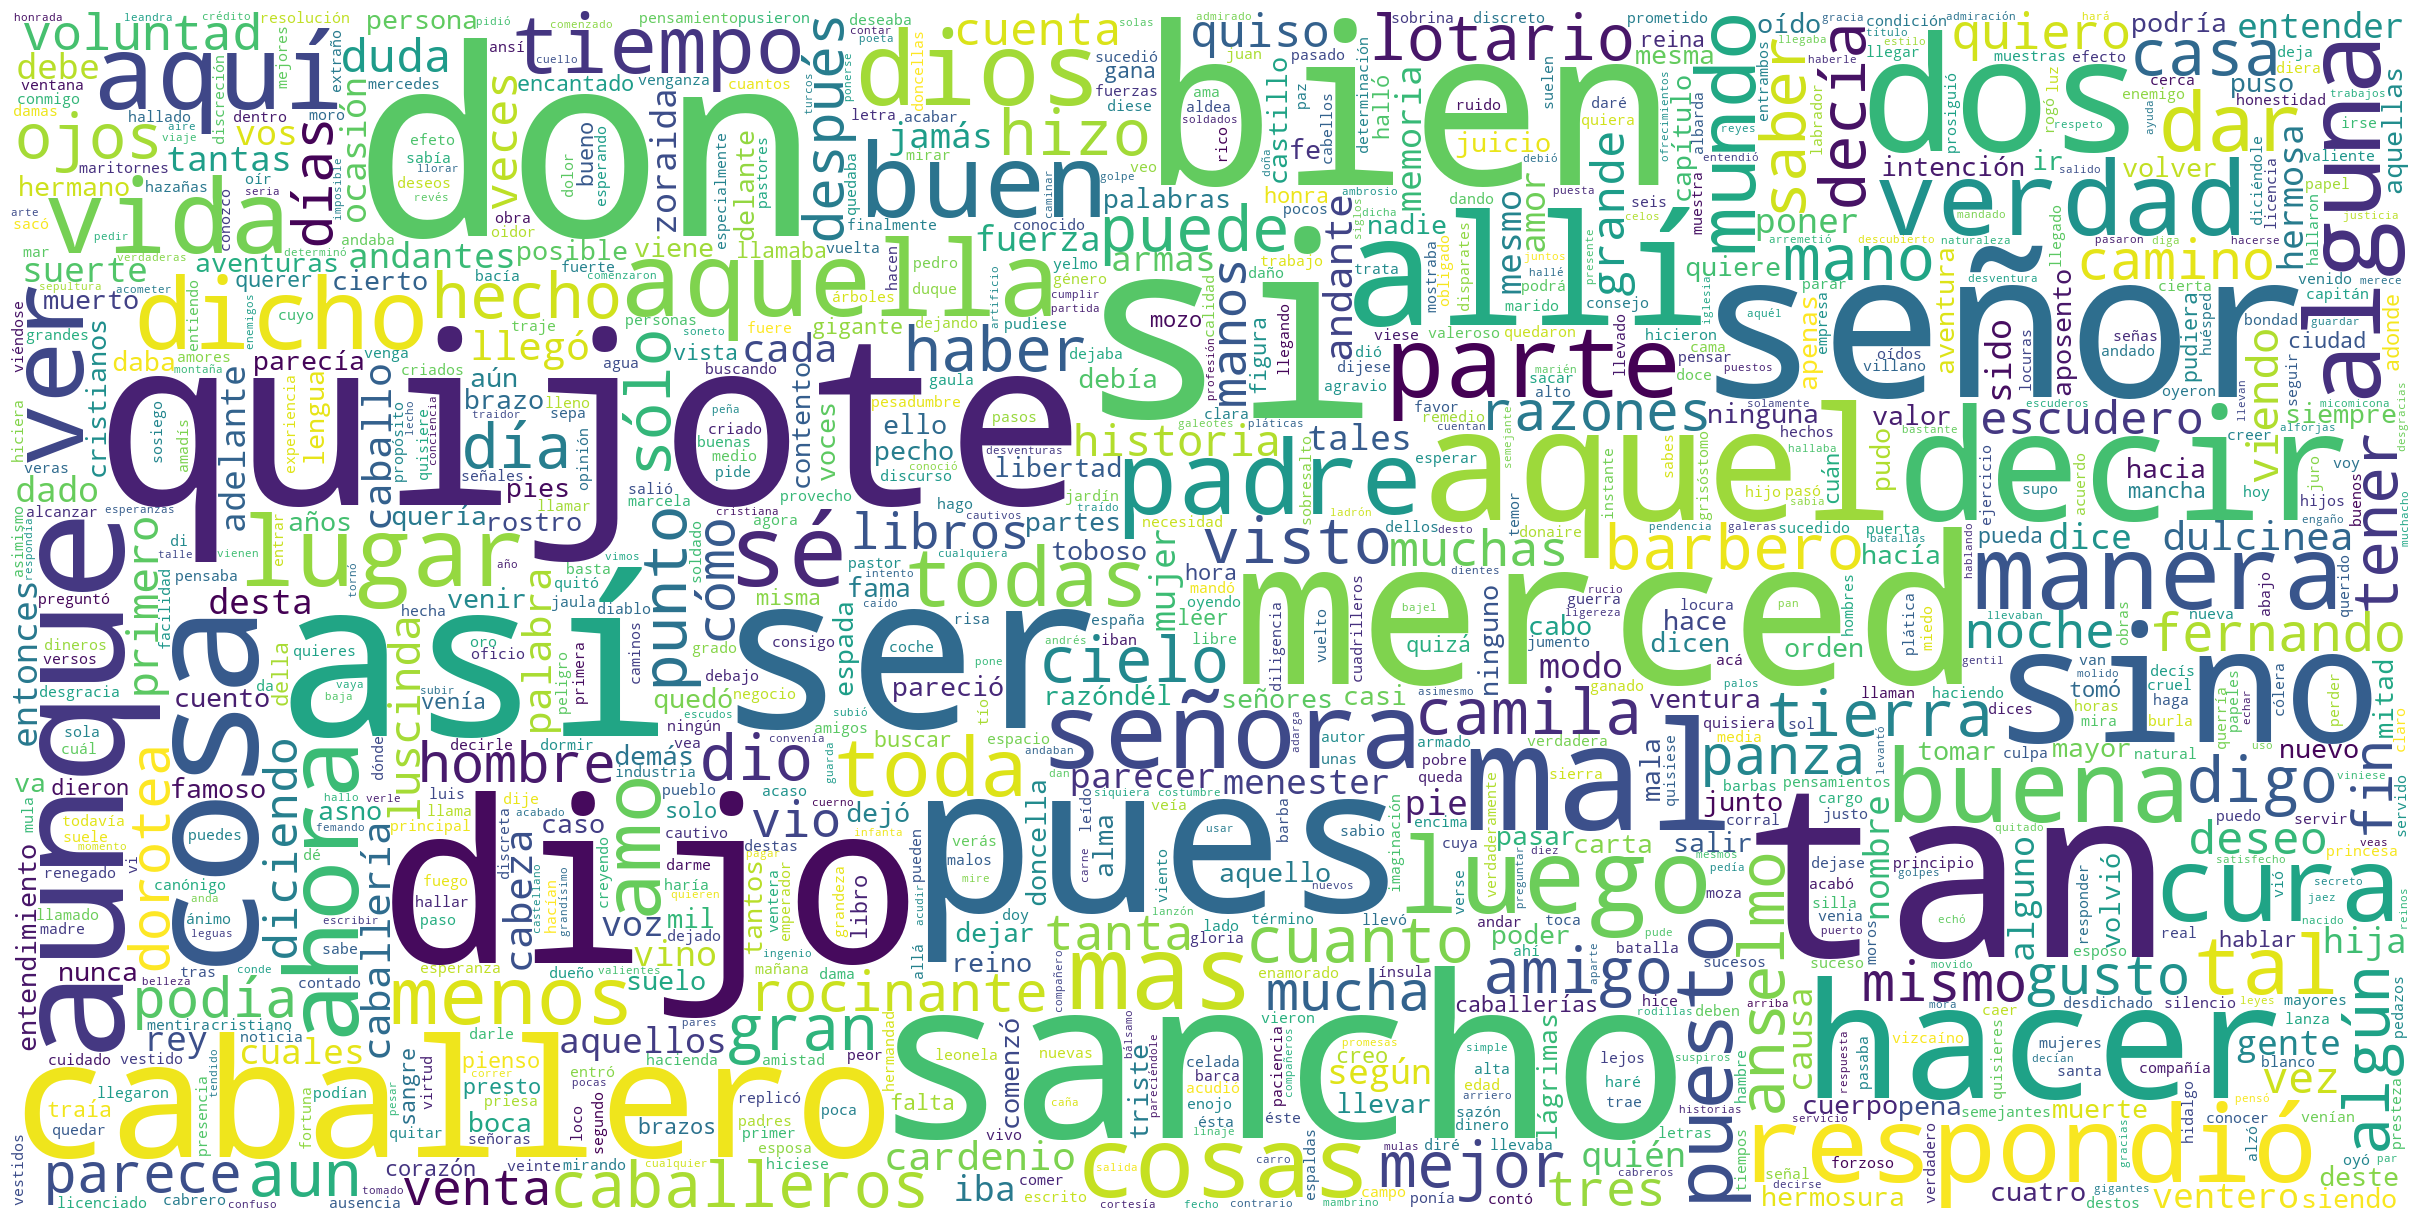

In [10]:
plt.figure(figsize=(24, 12))   # Figura más grande, proporcional a la imagen
plt.imshow(nube, interpolation='bilinear')
plt.axis('off')
plt.tight_layout(pad=0)
plt.show()

# Guardar la imagen en alta resolución
nube.to_file("wordcloud_quijote.png")